# Phase 1: Enhancement (sama, liver, patient 0)

I compare windowing, bilateral vs median, HE vs CLAHE and a Butterworth lowpass, and score them with PSNR and CNR.

## Step 0: Setup

Imports, folders and a slice loader.

In [1]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage.metrics import structural_similarity as ssim

NAME = "sama"                              # your slices folder
SLICES = "../data/slices/" + NAME
OUT = "outputs_sama"                       # creates phase1/outputs_sama
FIGS = "../report/figures/sama"
os.makedirs(OUT + "/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

# list all the CT slices of this member
files = sorted(glob.glob(SLICES + "/*_ct.npy"))
print(len(files), "slices found")

16 slices found


In [2]:
def load(ct_path):
    # load one slice: raw CT (HU) + liver mask + tumour mask (True/False)
    base = ct_path.replace("_ct.npy", "")
    ct = np.load(ct_path)
    liver_mask = cv2.imread(base + "_liver.png", 0) > 0
    tumour_mask = cv2.imread(base + "_tumour.png", 0) > 0
    return ct, liver_mask, tumour_mask

## Step 1: Load the image

The slice with the biggest tumour and its raw HU histogram.

In [3]:
# pick the slice with the biggest tumour to show in the figures
example = files[0]
biggest = -1
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    tumour_pixels = tumour_mask.sum()
    if tumour_pixels > biggest:
        biggest = tumour_pixels
        example = f

ct, liver_mask, tumour_mask = load(example)
print("example slice:", os.path.basename(example), "| tumour pixels:", tumour_mask.sum())
print("size:", ct.shape, "| HU range:", ct.min(), "to", ct.max())

example slice: p0_s58_ct.npy | tumour pixels: 538
size: (512, 512) | HU range: -3024.0 to 1155.0


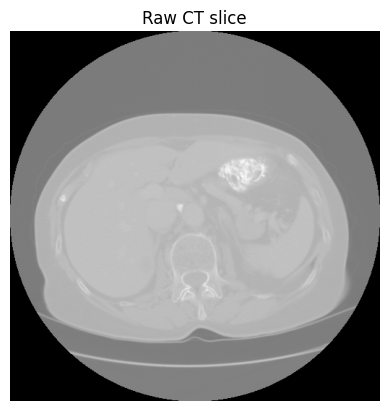

In [4]:
# show the raw CT (values are in HU, not 0-255)
plt.figure()
plt.imshow(ct, cmap='gray')
plt.title('Raw CT slice')
plt.axis('off')
plt.show()

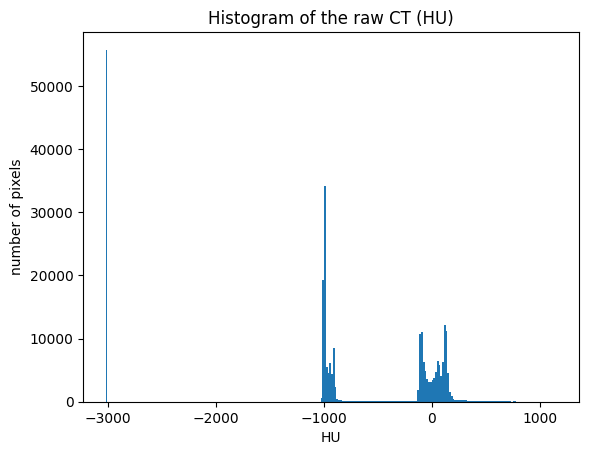

In [5]:
# look at the histogram: most HU values are air (about -1000) or soft tissue (about 0 to 100)
plt.figure()
plt.hist(ct.ravel(), bins=256)
plt.title('Histogram of the raw CT (HU)')
plt.xlabel('HU')
plt.ylabel('number of pixels')
plt.show()

## Step 2: Windowing

Keep -160 to 240 HU (level 40, width 400) and stretch it to 0-255.

In [6]:
def window(ct, level=40, width=400):
    # point processing s = T(r): keep the soft-tissue HU range and stretch it to 0-255
    low = level - width / 2                   # 40 - 200 = -160 HU
    high = level + width / 2                  # 40 + 200 = 240 HU
    img = np.clip(ct, low, high)              # everything outside -> low or high
    img = (img - low) / (high - low) * 255    # stretch to 0-255
    return img.astype(np.uint8)

windowed_img = window(ct)

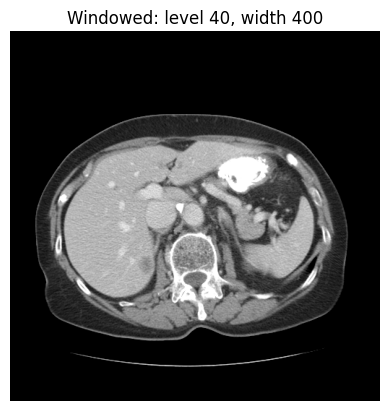

In [7]:
plt.figure()
plt.imshow(windowed_img, cmap='gray')
plt.title('Windowed: level 40, width 400')
plt.axis('off')
plt.show()

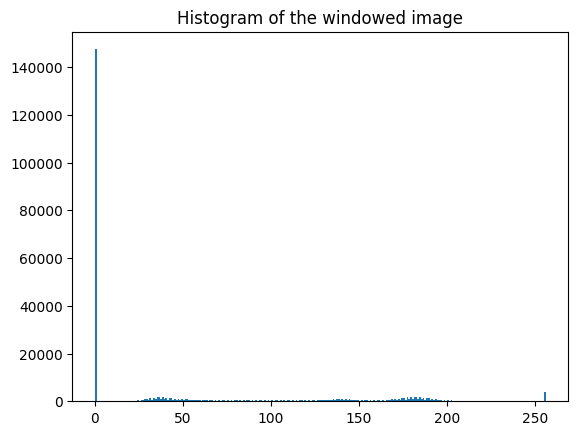

In [8]:
# histogram after windowing: the soft tissue now uses the whole 0-255 range
plt.figure()
plt.hist(windowed_img.ravel(), bins=256, range=(0, 256))
plt.title('Histogram of the windowed image')
plt.show()

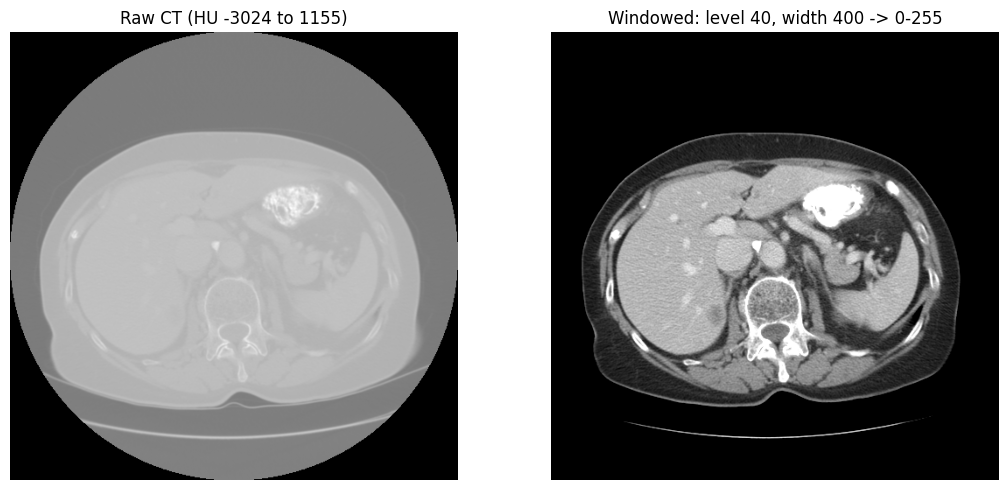

In [9]:
# save the comparison figure for the report
raw_title = "Raw CT (HU " + format(ct.min(), ".0f") + " to " + format(ct.max(), ".0f") + ")"

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(ct, cmap="gray")
ax[0].set_title(raw_title)
ax[1].imshow(windowed_img, cmap="gray")
ax[1].set_title("Windowed: level 40, width 400 -> 0-255")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_windowing.png", dpi=120)
plt.show()

## Step 3: Bilateral vs median

Median takes the middle value of each 5x5 window. Bilateral only averages pixels that are close and similar, so edges stay sharp.

In [10]:
# bilateral filter: d = 9 pixel neighbourhood, sigmaColor = 40, sigmaSpace = 9
bilateral_img = cv2.bilateralFilter(windowed_img, d=9, sigmaColor=40, sigmaSpace=9)

# median filter with a 5x5 window
median_img = cv2.medianBlur(windowed_img, 5)

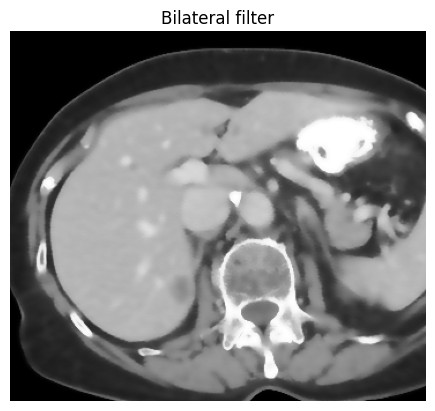

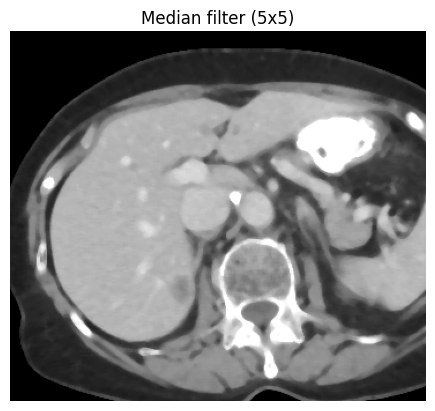

In [11]:
# zoom on the abdomen centre (rows 100-420, columns 40-400) so the liver is easier to see
plt.figure()
plt.imshow(bilateral_img[100:420, 40:400], cmap='gray')
plt.title('Bilateral filter')
plt.axis('off')
plt.show()

plt.figure()
plt.imshow(median_img[100:420, 40:400], cmap='gray')
plt.title('Median filter (5x5)')
plt.axis('off')
plt.show()

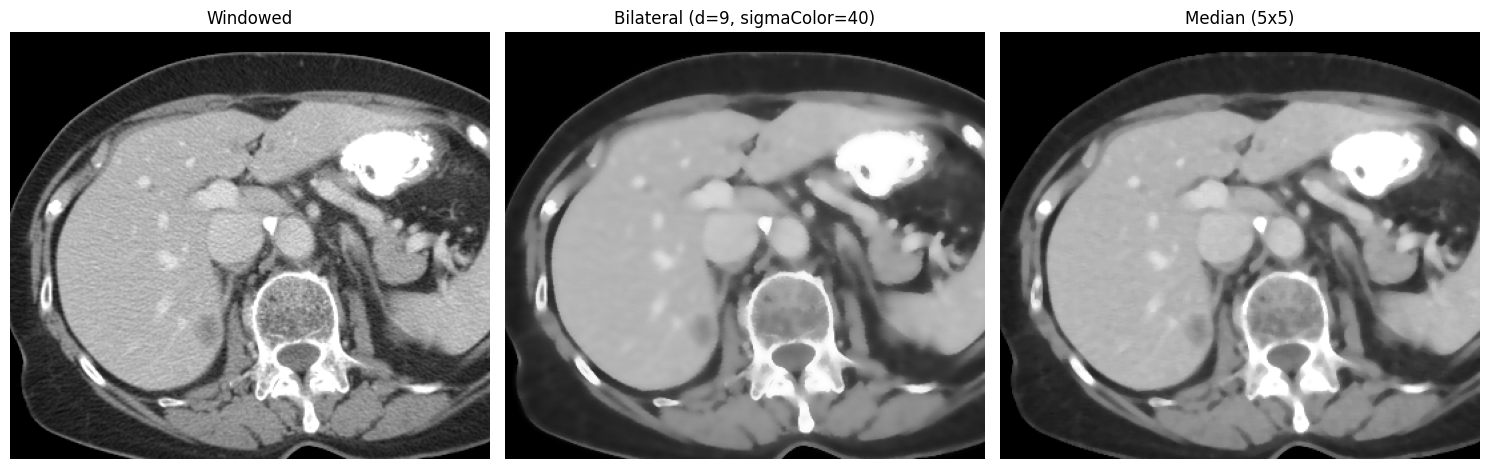

In [12]:
# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(windowed_img[100:420, 40:400], cmap="gray")
ax[0].set_title("Windowed")
ax[1].imshow(bilateral_img[100:420, 40:400], cmap="gray")
ax[1].set_title("Bilateral (d=9, sigmaColor=40)")
ax[2].imshow(median_img[100:420, 40:400], cmap="gray")
ax[2].set_title("Median (5x5)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_spatial_filters.png", dpi=120)
plt.show()

## Step 4: Histogram equalisation vs CLAHE

HE works on the whole image; CLAHE works in 8x8 tiles with clip limit 2.0 so noise is not over-boosted.

In [13]:
# histogram equalisation of the bilateral output
he_img = cv2.equalizeHist(bilateral_img)

# CLAHE: clip limit 2.0, 8x8 tiles
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(bilateral_img)

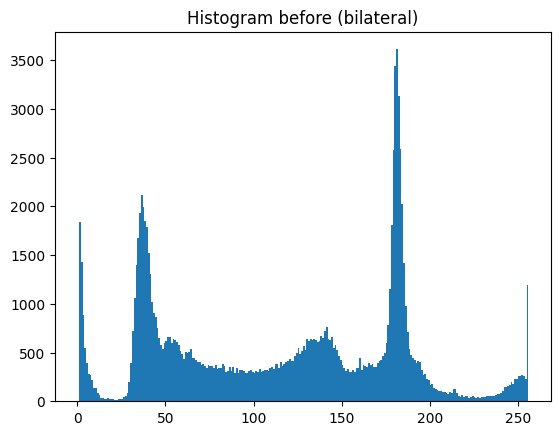

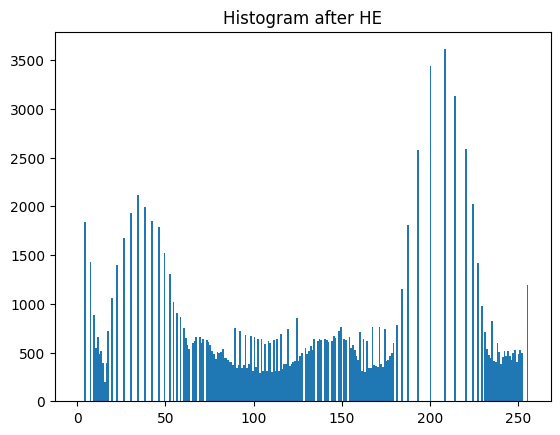

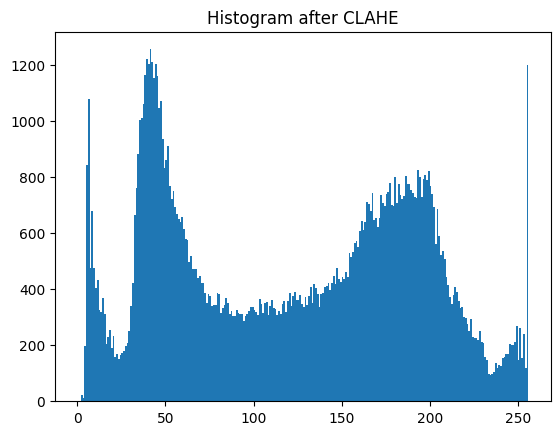

In [14]:
# only look at pixels inside the body (ignore the black surround)
body = bilateral_img > 0

# look at the histogram before and after equalisation
plt.figure()
plt.hist(bilateral_img[body].ravel(), bins=256, range=(0, 256))
plt.title('Histogram before (bilateral)')
plt.show()

plt.figure()
plt.hist(he_img[body].ravel(), bins=256, range=(0, 256))
plt.title('Histogram after HE')
plt.show()

plt.figure()
plt.hist(clahe_img[body].ravel(), bins=256, range=(0, 256))
plt.title('Histogram after CLAHE')
plt.show()

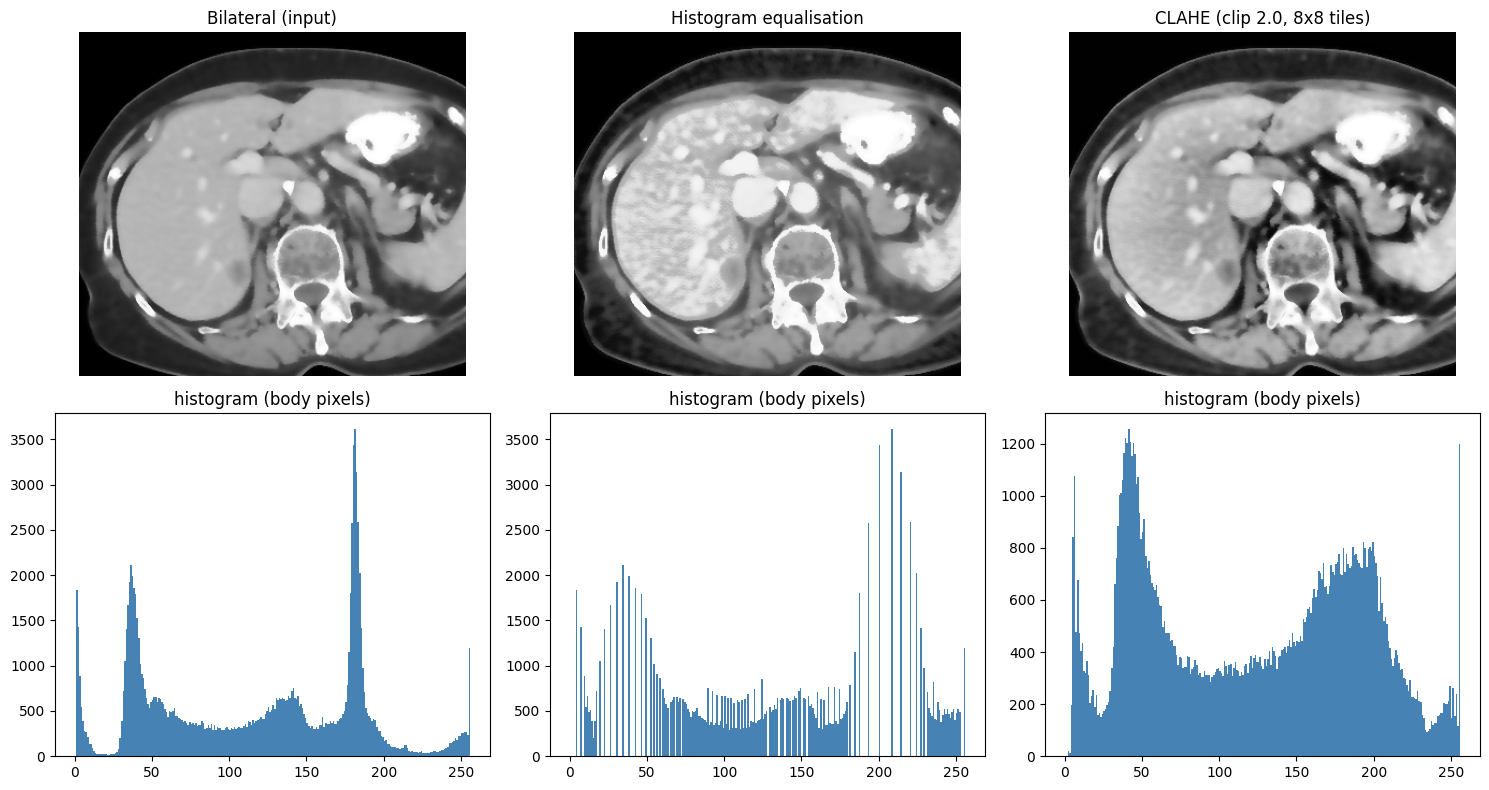

In [15]:
# save the comparison figure for the report (images on top, histograms below)
contrast_images = [bilateral_img, he_img, clahe_img]
contrast_titles = ["Bilateral (input)", "Histogram equalisation", "CLAHE (clip 2.0, 8x8 tiles)"]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j in range(3):
    img = contrast_images[j]
    ax[0, j].imshow(img[100:420, 40:400], cmap="gray")
    ax[0, j].set_title(contrast_titles[j])
    ax[0, j].axis("off")
    ax[1, j].hist(img[body].ravel(), bins=256, range=(0, 256), color="steelblue")
    ax[1, j].set_title("histogram (body pixels)")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_contrast.png", dpi=120)
plt.show()

## Step 5: Butterworth lowpass

DFT, spectrum, H(u,v) with D0 = 60 and n = 2, multiply, inverse DFT.

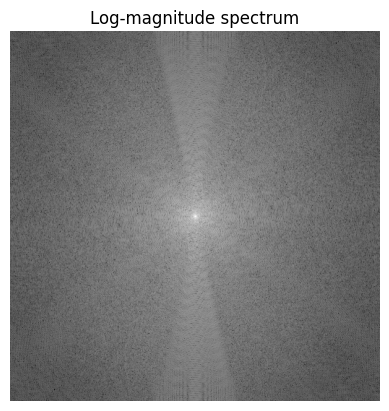

In [16]:
# 2D DFT, then move the low frequencies to the centre
F = np.fft.fft2(windowed_img.astype(np.float64))
F = np.fft.fftshift(F)

# log-magnitude spectrum, log(1 + |F|), so it can be displayed
spectrum = np.log(1 + np.abs(F))

plt.figure()
plt.imshow(spectrum, cmap='gray')
plt.title('Log-magnitude spectrum')
plt.axis('off')
plt.show()

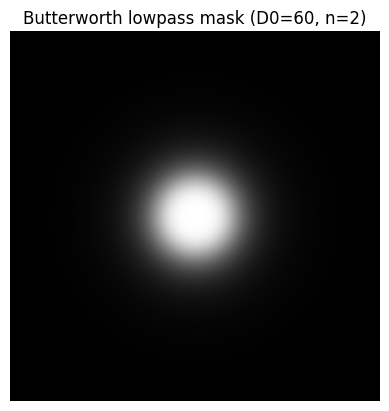

In [17]:
# build the Butterworth lowpass filter, D0 = 60, order n = 2
D0 = 60
n = 2
rows, cols = windowed_img.shape
u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
D = np.sqrt(u**2 + v**2)                  # D(u,v) = distance from the centre
H = 1 / (1 + (D / D0) ** (2 * n))         # Butterworth lowpass formula

plt.figure()
plt.imshow(H, cmap='gray')
plt.title('Butterworth lowpass mask (D0=60, n=2)')
plt.axis('off')
plt.show()

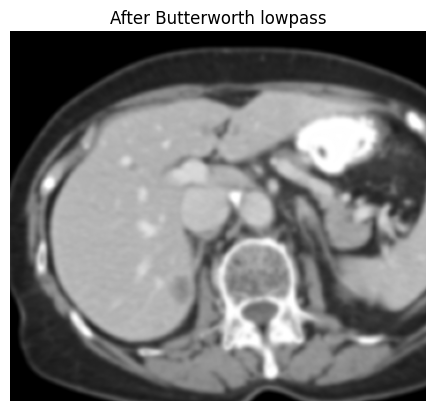

In [18]:
# multiply in the frequency domain, then inverse DFT back to an image
G = F * H
G = np.fft.ifftshift(G)
butterworth_img = np.real(np.fft.ifft2(G))
butterworth_img = np.clip(butterworth_img, 0, 255).astype(np.uint8)

plt.figure()
plt.imshow(butterworth_img[100:420, 40:400], cmap='gray')
plt.title('After Butterworth lowpass')
plt.axis('off')
plt.show()

In [19]:
# the same steps as a function, so it can be used on every slice below
def butterworth_lowpass(img, D0=60, n=2):
    F = np.fft.fft2(img.astype(np.float64))
    F = np.fft.fftshift(F)
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D = np.sqrt(u**2 + v**2)
    H = 1 / (1 + (D / D0) ** (2 * n))
    G = np.fft.ifftshift(F * H)
    out = np.real(np.fft.ifft2(G))
    out = np.clip(out, 0, 255).astype(np.uint8)
    return out

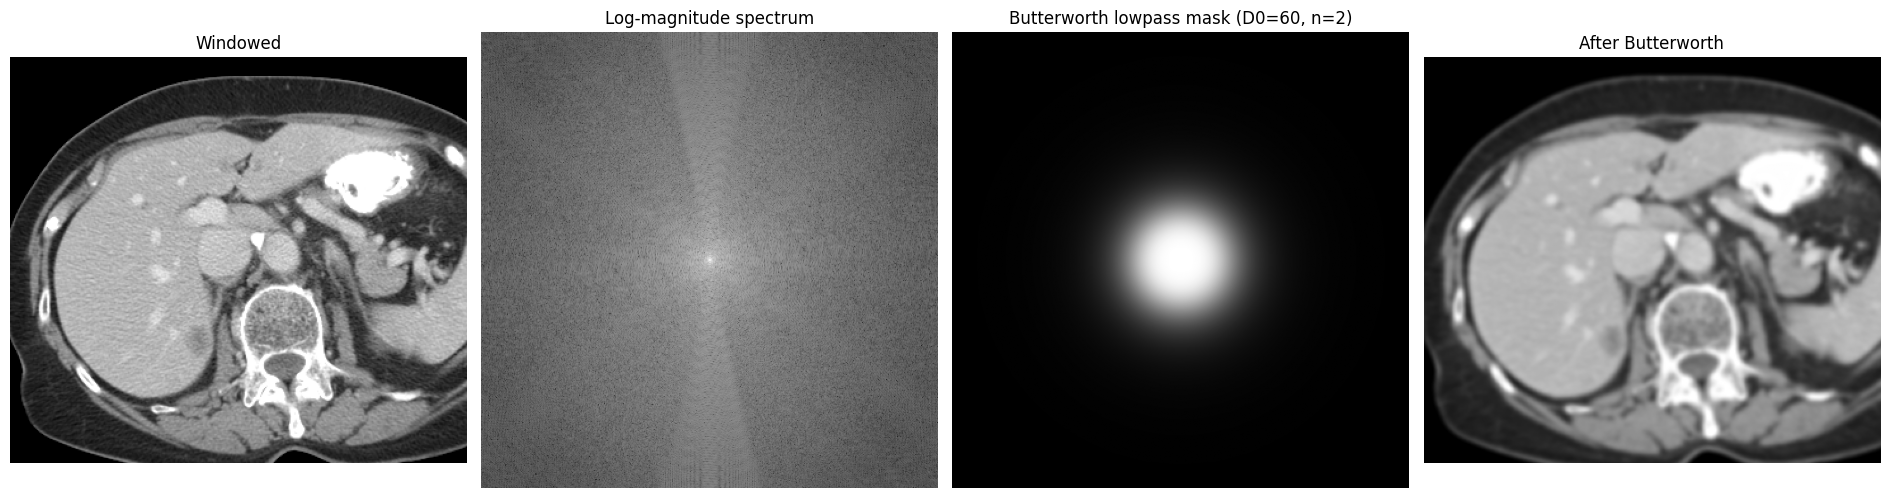

In [20]:
# save the comparison figure for the report
fig, ax = plt.subplots(1, 4, figsize=(19, 5))
ax[0].imshow(windowed_img[100:420, 40:400], cmap="gray")
ax[0].set_title("Windowed")
ax[1].imshow(spectrum, cmap="gray")
ax[1].set_title("Log-magnitude spectrum")
ax[2].imshow(H, cmap="gray")
ax[2].set_title("Butterworth lowpass mask (D0=60, n=2)")
ax[3].imshow(butterworth_img[100:420, 40:400], cmap="gray")
ax[3].set_title("After Butterworth")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_frequency.png", dpi=120)
plt.show()

## Step 6: Validation on all slices

PSNR shows how much a method changed the image, CNR how well the liver or tumour stands out.

In [21]:
def psnr(ref, test):
    # how close the processed image stays to the original (dB). Higher = less changed
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10(255 ** 2 / mse)


def cnr(img, region, background):
    # how well a region stands out from its background. Higher = easier to see
    a = img[region].astype(np.float64)
    b = img[background].astype(np.float64)
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var())

In [22]:
# 25x25 square structuring element for the dilation
square_se = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

metric_rows = []
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    slice_name = os.path.basename(f).replace("_ct.npy", "")
    windowed_img = window(ct)

    # healthy liver = liver without the tumour
    healthy_liver = liver_mask & ~tumour_mask

    # dilate the liver, then remove the liver -> a ring of surrounding tissue
    dilated_liver = cv2.dilate(liver_mask.astype(np.uint8), square_se)
    ring = dilated_liver.astype(bool) & ~liver_mask

    # all the versions of this slice
    bilateral_img = cv2.bilateralFilter(windowed_img, d=9, sigmaColor=40, sigmaSpace=9)
    versions = {}
    versions["windowed"] = windowed_img
    versions["bilateral"] = bilateral_img
    versions["median"] = cv2.medianBlur(windowed_img, 5)
    versions["butterworth"] = butterworth_lowpass(windowed_img)
    versions["bilateral+HE"] = cv2.equalizeHist(bilateral_img)
    versions["bilateral+CLAHE"] = clahe.apply(bilateral_img)

    for method in versions:
        img = versions[method]
        # the windowed image is the reference, so it has no PSNR
        if method == "windowed":
            psnr_value = np.nan
        else:
            psnr_value = psnr(windowed_img, img)
        row = {}
        row["slice"] = slice_name
        row["method"] = method
        row["PSNR"] = psnr_value
        row["CNR liver vs surroundings"] = cnr(img, liver_mask, ring)
        row["CNR tumour vs liver"] = cnr(img, tumour_mask, healthy_liver)
        metric_rows.append(row)

results = pd.DataFrame(metric_rows)
results.to_csv(OUT + "/phase1_metrics.csv", index=False)

In [23]:
# average of each method over all slices
metric_columns = ["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]
summary = results.groupby("method", sort=False)[metric_columns].mean()
summary = summary.round(2)
print(summary)

                  PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                                
windowed           NaN                       1.28                 1.04
bilateral        33.53                       1.31                 1.18
median           27.87                       1.31                 1.21
butterworth      27.98                       1.34                 1.16
bilateral+HE     24.40                       1.43                 1.35
bilateral+CLAHE  26.62                       1.29                 1.22


## Step 7: Controlled noise test

We add 40 HU Gaussian noise before windowing and measure PSNR and SSIM against the clean slice on tissue pixels only.

In [24]:
NOISE_SIGMA_HU = 40      # same physical noise for every member, added in HU BEFORE windowing
noise_rng = np.random.default_rng(0)

metric_rows = []
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    slice_name = os.path.basename(f).replace("_ct.npy", "")
    clean_img = window(ct)

    # add Gaussian noise in HU, then window (the window scales the noise like real CT noise)
    noise = noise_rng.normal(0, NOISE_SIGMA_HU, ct.shape)
    noisy_img = window(ct + noise)

    # score only unclipped tissue (no black air or white bone)
    tissue = (clean_img > 0) & (clean_img < 255)

    filtered = {}
    filtered["noisy (no filter)"] = noisy_img
    filtered["bilateral"] = cv2.bilateralFilter(noisy_img, d=9, sigmaColor=40, sigmaSpace=9)
    filtered["median"] = cv2.medianBlur(noisy_img, 5)
    filtered["butterworth"] = butterworth_lowpass(noisy_img)

    for method in filtered:
        img = filtered[method]
        score, ssim_map = ssim(clean_img, img, data_range=255, full=True)
        row = {}
        row["slice"] = slice_name
        row["method"] = method
        row["PSNR vs clean"] = psnr(clean_img[tissue], img[tissue])
        row["SSIM vs clean"] = ssim_map[tissue].mean()
        metric_rows.append(row)

noise_test = pd.DataFrame(metric_rows)
noise_test.to_csv(OUT + "/phase1_noise_test.csv", index=False)

In [25]:
# average of each filter over all slices
print("Added Gaussian noise in HU, sigma =", NOISE_SIGMA_HU, "HU (before windowing):")
noise_summary = noise_test.groupby("method", sort=False)[["PSNR vs clean", "SSIM vs clean"]].mean()
noise_summary = noise_summary.round(3)
print(noise_summary)

Added Gaussian noise in HU, sigma = 40 HU (before windowing):
                   PSNR vs clean  SSIM vs clean
method                                         
noisy (no filter)         20.208          0.460
bilateral                 25.547          0.684
median                    22.583          0.671
butterworth               24.371          0.715


## Step 8: Final enhancement

Windowing, then bilateral, then CLAHE: bilateral had the best PSNR and CLAHE looks natural. HE gives a higher tumour CNR but makes the liver grainy.

In [26]:
# apply the final chain to every slice and save it for Phase 2
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    windowed_img = window(ct)                                                             # Step 2
    bilateral_img = cv2.bilateralFilter(windowed_img, d=9, sigmaColor=40, sigmaSpace=9)   # Step 3
    enhanced_img = clahe.apply(bilateral_img)                                             # Step 4
    out_name = os.path.basename(f).replace("_ct.npy", "_enh.png")
    cv2.imwrite(OUT + "/enhanced/" + out_name, enhanced_img)

print("saved", len(files), "enhanced slices to", OUT + "/enhanced")

saved

 16 enhanced slices to outputs_sama/enhanced


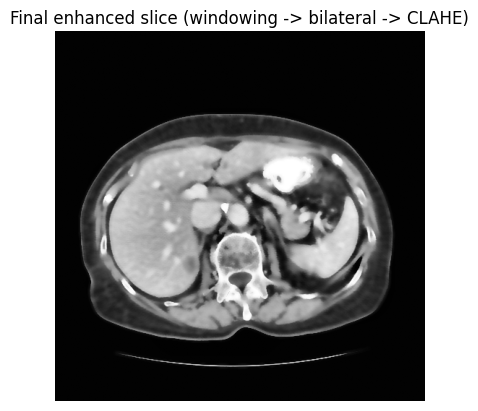

In [27]:
# show one final enhanced slice
example_name = os.path.basename(example).replace("_ct.npy", "_enh.png")
enhanced_example = cv2.imread(OUT + "/enhanced/" + example_name, 0)
plt.figure()
plt.imshow(enhanced_example, cmap='gray')
plt.title('Final enhanced slice (windowing -> bilateral -> CLAHE)')
plt.axis('off')
plt.show()